# Explanation Evaluation
To evaluate the performance of my explanations, I need to compute the AUROC curve. I will do that for three cases:
- Token-Level Probabilities (baseline)
- Explanations Similarity
- Random Forest - Explanations Similarity + Linter Features

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from sklearn.metrics import roc_curve, auc

In [2]:
ground_truth = pd.read_csv('datasets/evaluation_python_solutions_1.csv')

In [3]:
ground_truth.shape

(1160, 14)

In [4]:
ground_truth.head()

,problem_title,code_line,is_readable,correct_naming,has_good_length,is_logic_straightforward,is_consistently_formatted,avoid_side_effects,dry,respect_language_practice,error_handling,extreme_error,sum_criteria,good
0,Sports Rank,def read_input():,1,0,1,1,1,1,1,1,1,0,8,1
1,Sports Rank,import sys,1,1,1,1,1,1,1,0,1,0,8,1
2,Sports Rank,input = sys.stdin.read,1,0,1,1,1,1,1,0,1,0,7,0
3,Sports Rank,data = input().split(),1,0,1,1,1,1,1,1,0,0,7,0
4,Sports Rank,index = 0,1,1,1,1,1,1,1,1,1,0,9,1


In [5]:
ground_truth_classes = list(map(int, list(ground_truth['good'])))

In [6]:
def plot_multiple_roc_curves(roc_data):
    """
    roc_data: list of tuples (label, y_true, y_score)
    """
    fig = go.Figure()

    for label, y_true, y_score in roc_data:
        fpr, tpr, _ = roc_curve(y_true, y_score)
        roc_auc = auc(fpr, tpr)

        fig.add_trace(
            go.Scatter(
                x=fpr, y=tpr,
                mode='lines',
                name=f'{label} (AUROC = {roc_auc:.4f})'
            )
        )

    # Add diagonal
    fig.add_trace(
        go.Scatter(
            x=[0, 1], y=[0, 1],
            mode='lines',
            name='Random chance',
            line=dict(dash='dash', color='gray')
        )
    )

    fig.update_layout(
        title='ROC Curves',
        xaxis_title='False Positive Rate',
        yaxis_title='True Positive Rate',
        xaxis=dict(range=[0, 1]),
        yaxis=dict(range=[0, 1.05]),
        legend=dict(x=0.6, y=0.05),
        width=700,
        height=500
    )

    fig.show()

In [7]:
def get_auroc(ground_truth, predicted_probs):
    fpr, tpr, thresholds = roc_curve(ground_truth, predicted_probs)
    plot_roc_curve(fpr, tpr)

## Baseline

In [8]:
baseline_probabilities = pd.read_csv('datasets/probabilities_python_final.csv')

In [9]:
baseline_probabilities = baseline_probabilities[baseline_probabilities['line_number'] != 0]
baseline_probabilities = baseline_probabilities[baseline_probabilities['line_text'].str.strip() != '']
baseline_probabilities = baseline_probabilities[~baseline_probabilities['line_text'].str.strip().str.startswith('#')]
baseline_probabilities

,title,line_number,line_text,token_prob
1,Sports Rank,1,def read_input():\n,0.667149
2,Sports Rank,2,import sys\n,0.972428
3,Sports Rank,3,input = sys.stdin.read\n,0.992203
4,Sports Rank,4,data = input().split()\n,0.992855
6,Sports Rank,6,index = 0\n,0.939398
...,...,...,...,...
1353,New Distinct Substrings,39,string = data[index]\n,0.865940
1354,New Distinct Substrings,40,index += 1\n,0.921482
1355,New Distinct Substrings,41,results.append(count_distinct_substrings(s...,0.955230
1356,New Distinct Substrings,43,for result in results:\n,0.999838


In [10]:
baseline_probabilities.shape

(1160, 4)

## Similarity

In [17]:
all_probabilities = pd.read_csv('datasets/all_probabilities.csv')

In [18]:
roc_data = [
    ('Baseline', ground_truth_classes, list(baseline_probabilities['token_prob'])),
    ('Similarity 2', ground_truth_classes, list(all_probabilities['similarity_2'])),
    ('Similarity 3', ground_truth_classes, list(all_probabilities['similarity_3'])),
    ('Similarity 4', ground_truth_classes, list(all_probabilities['similarity_4'])),
    ('Similarity 5', ground_truth_classes, list(all_probabilities['similarity_5'])),
    ('RF with Sim', ground_truth_classes, list(all_probabilities['rf_with_sim']))
]

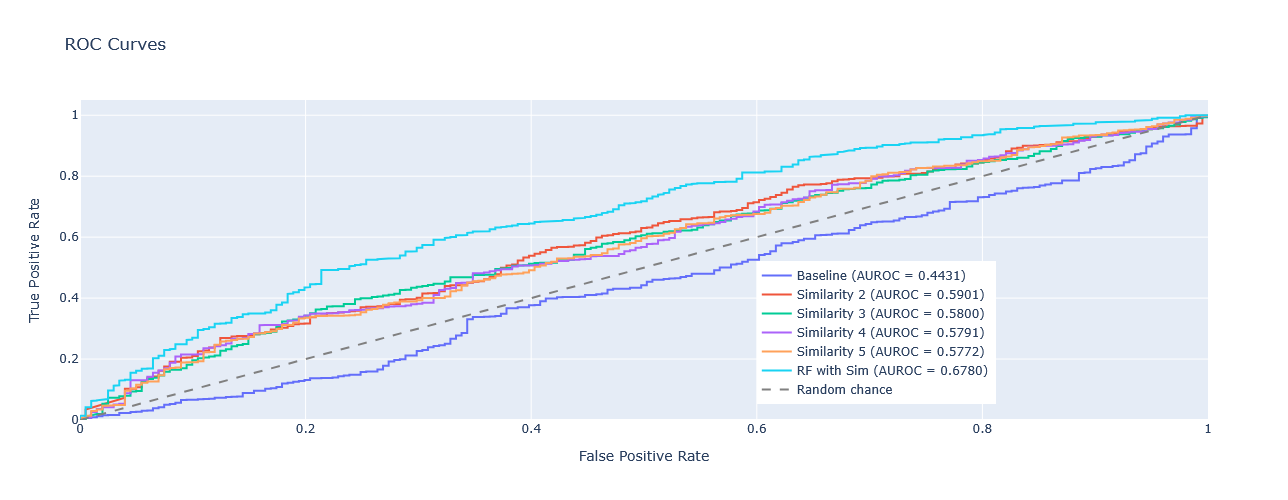

In [16]:
plot_multiple_roc_curves(roc_data)

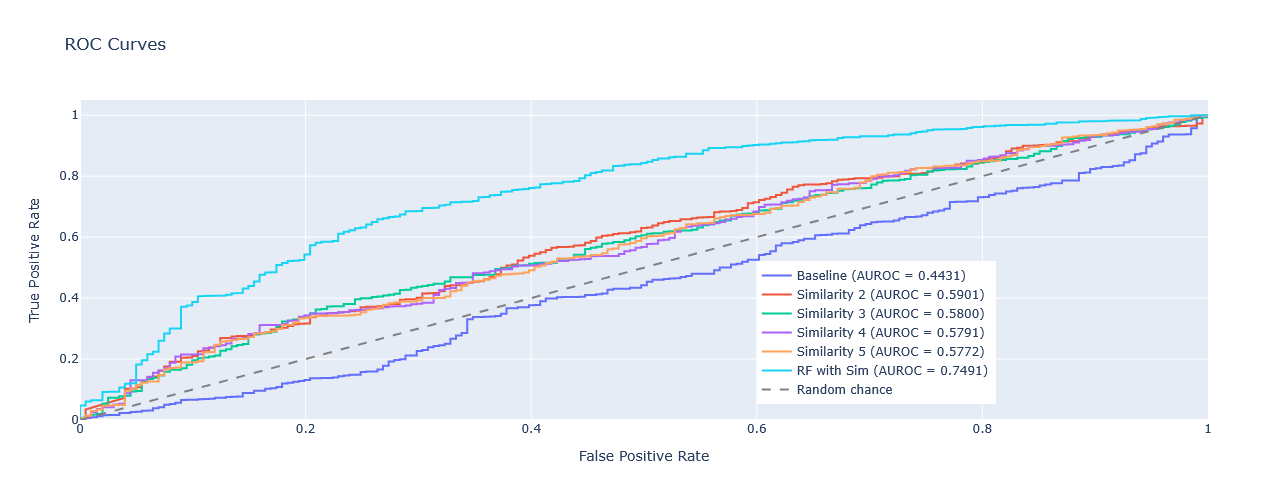

In [19]:
plot_multiple_roc_curves(roc_data)